# Práctica 2 — Media-varianza y modelos multifactoriales

**Pregunta de fondo:** ¿lo que parece alfa lo sigue pareciendo cuando se controla por factores?

* **Parte A** (`quantmgmt.optimizers`): frontera eficiente de Markowitz con restricciones realistas, referencias (equiponderada, SPY, SML del CAPM) y prueba fuera de muestra.
* **Parte B** (`quantmgmt.analytics`): descomposición de la rentabilidad en primas de riesgo con CAPM, FF3, Carhart y FF5.

**Universo:** 10 ETFs sectoriales de EE. UU. más SPY, datos mensuales desde 2010.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from matplotlib.ticker import PercentFormatter

from quantmgmt.data import YahooFinanceData, excess_returns, get_factors, monthly_returns
from quantmgmt.optimizers import (
    Constraints,
    effective_n,
    efficient_frontier,
    estimate_inputs,
    max_sharpe,
    min_variance,
    portfolio_return,
    portfolio_volatility,
)
from quantmgmt.analytics import compare_models, rolling_betas, run_factor_regression
from quantmgmt.utils import generate_risk_summary

plt.rcParams["figure.figsize"] = (12, 5)
plt.rcParams["axes.grid"] = True
pd.set_option("display.width", 200)

## 0. Datos

* **ETFs:** precios mensuales ajustados por dividendos (`Adj Close`) de yfinance, con caché en `data/cache/`. Se descarta el mes en curso si está incompleto.
* **Factores:** Ken French Data Library vía `pandas_datareader`. Vienen en % y ya en exceso sobre el tipo libre de riesgo: se pasan a tanto por uno, y a los ETFs se les resta el `RF` del mismo fichero.
* **Fechas:** todo se indexa por mes (`PeriodIndex`) para que ETFs y factores casen sin desfases.

In [2]:
SECTORS = ["XLK", "XLF", "XLE", "XLV", "XLI", "XLY", "XLP", "XLU", "XLB", "XLRE"]
BENCHMARK = "SPY"
TODAY = pd.Timestamp.today().strftime("%Y-%m-%d")

prices = YahooFinanceData().get_prices(SECTORS + [BENCHMARK], "2010-01-01", TODAY, interval="1mo")
returns = monthly_returns(prices)[SECTORS + [BENCHMARK]]   # retornos totales
factors = get_factors(start="2010-01")
rf = factors["ff3"]["RF"]

ex = excess_returns(returns, rf)                              # retornos en exceso
returns = returns.loc[ex.index]                               # mismos meses que los factores
RF_ANNUAL = rf.loc[ex.index].mean() * 12

print(f"Meses: {ex.index[0]} -> {ex.index[-1]} ({len(ex)})   rf medio anual: {RF_ANNUAL:.2%}")
ex.count().to_frame("meses con dato").T

Meses: 2010-02 -> 2026-08 (199)   rf medio anual: 1.42%


,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,XLRE,SPY
meses con dato,199,199,199,199,199,199,199,199,199,130,199


**Decisión sobre XLRE.** XLRE empieza a cotizar en octubre de 2015. Para optimizar hace falta una covarianza con todos los activos en los mismos meses (si no, la matriz puede no ser semidefinida positiva y el optimizador da resultados sin sentido). Opciones: recortar toda la muestra a 2015-2026 o excluir XLRE de la optimización.

Se **excluye XLRE de la Parte A** (optimización) y se mantiene en la SML y en la Parte B, donde cada regresión usa los meses disponibles de cada activo. Así la Parte A conserva la ventana 2010-2017 que exige la prueba fuera de muestra, y XLRE solo pierde el papel de candidato en la cartera.

In [3]:
OPT = [s for s in SECTORS if s != "XLRE"]   # universo de la optimización (9 sectores)

ex_opt = ex[OPT].dropna()
mu, cov = estimate_inputs(ex_opt, periods_per_year=12)   # en exceso -> rf = 0 en el Sharpe

pd.DataFrame({
    "Rentabilidad exceso (anual)": mu,
    "Volatilidad (anual)": np.sqrt(np.diag(cov)),
}, index=OPT).style.format("{:.1%}")

,Rentabilidad exceso (anual),Volatilidad (anual)
XLK,19.1%,18.6%
XLF,11.8%,18.4%
XLE,10.6%,26.7%
XLV,11.5%,13.7%
XLI,13.3%,17.8%
XLY,14.1%,18.3%
XLP,9.1%,12.1%
XLU,9.4%,14.2%
XLB,10.0%,18.8%


## Parte A — Optimización media-varianza

### A.1 Frontera eficiente: efecto de las restricciones

Tres fronteras sobre la muestra completa:

* **Con cortos**: sin restricciones de signo.
* **Long-only**: sin cortos, sin límite por activo.
* **Long-only con máximo 20 %** por activo.

La concentración se mide con el **número efectivo de activos**, $N_{ef} = 1/\sum w_i^2$: vale 9 si la cartera es equiponderada entre los 9 sectores y 1 si todo está en uno.

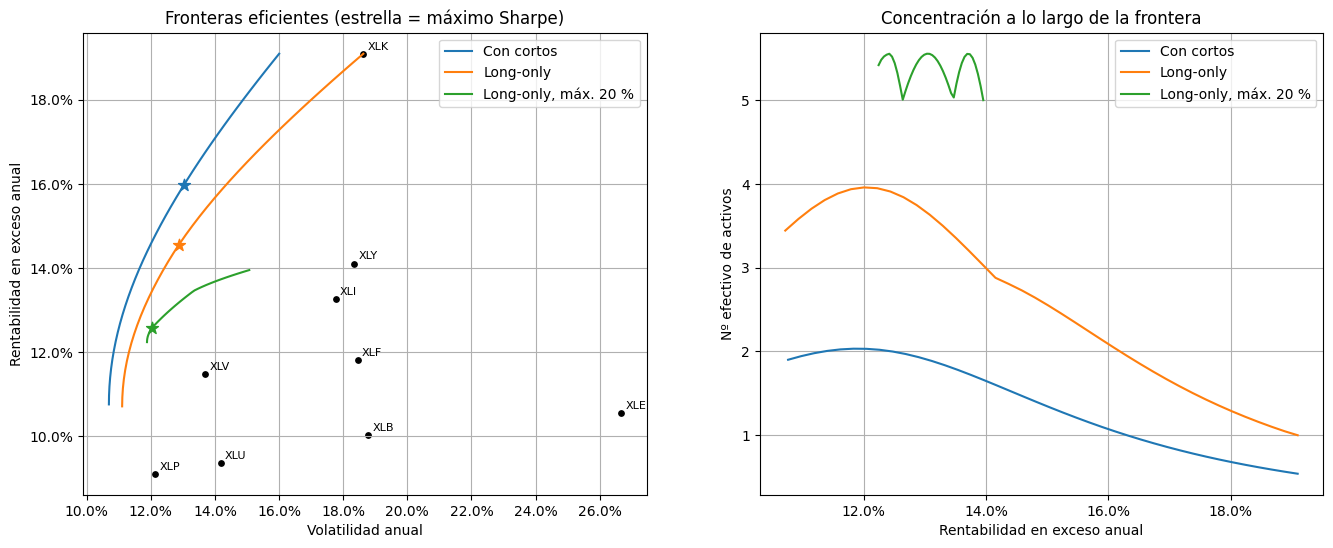

In [16]:
SETUPS = {
    "Con cortos": Constraints(long_only=False),
    "Long-only": Constraints(),
    "Long-only, máx. 20 %": Constraints(max_weight=0.20),
}

frontiers = {name: efficient_frontier(mu, cov, n_points=40, constraints=c) for name, c in SETUPS.items()}
tangency = {name: max_sharpe(mu, cov, constraints=c) for name, c in SETUPS.items()}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
for name, f in frontiers.items():
    ax1.plot(f["volatility"], f["return"], label=name)
    w = tangency[name]
    ax1.scatter(portfolio_volatility(w, cov), portfolio_return(w, mu), s=80, marker="*", zorder=5)
    ax2.plot(f["return"], f["effective_n"], label=name)

ax1.scatter(np.sqrt(np.diag(cov)), mu, color="black", s=15)
for t in OPT:
    ax1.annotate(t, (np.sqrt(cov.loc[t, t]), mu[t]), fontsize=8, xytext=(3, 3), textcoords="offset points")
ax1.set(xlabel="Volatilidad anual", ylabel="Rentabilidad en exceso anual", title="Fronteras eficientes (estrella = máximo Sharpe)")
ax2.set(xlabel="Rentabilidad en exceso anual", ylabel="Nº efectivo de activos", title="Concentración a lo largo de la frontera")
for ax in (ax1, ax2):
    ax.legend()
ax1.xaxis.set_major_formatter(PercentFormatter(1.0)); ax1.yaxis.set_major_formatter(PercentFormatter(1.0))
ax2.xaxis.set_major_formatter(PercentFormatter(1.0))
plt.show()

In [17]:
weights_table = pd.DataFrame(tangency).T
weights_table["Sharpe"] = [portfolio_return(w, mu) / portfolio_volatility(w, cov) for w in tangency.values()]
weights_table["N efectivo"] = [effective_n(w) for w in tangency.values()]
weights_table["Activos con peso > 1 %"] = [(w > 0.01).sum() for w in tangency.values()]

weights_table.style.format({**{t: "{:.1%}" for t in OPT}, "Sharpe": "{:.2f}", "N efectivo": "{:.1f}"})

,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,Sharpe,N efectivo,Activos con peso > 1 %
Con cortos,62.2%,3.8%,7.5%,44.1%,8.2%,-11.4%,6.3%,27.9%,-48.5%,1.23,1.1,7
Long-only,47.9%,0.0%,0.0%,25.2%,0.0%,0.0%,0.0%,26.9%,0.0%,1.13,2.7,3
"Long-only, máx. 20 %",20.0%,2.9%,0.0%,20.0%,0.0%,17.1%,20.0%,20.0%,0.0%,1.04,5.3,6


**Comentario:**

* **Con cortos**, la frontera es la más alta (máximo Sharpe con ~16 % de rentabilidad en exceso y ~13 % de volatilidad), pero a costa de posiciones extremas. El N efectivo baja de 1 en la parte alta de la frontera: la cartera está apalancada, con pesos superiores al 100 % en unos sectores financiados con cortos en otros. No es implementable para un inversor long-only y depende por completo de unas estimaciones de `mu` muy ruidosas.
* **Long-only**, la concentración depende de dónde se esté en la frontera. Cerca de la mínima varianza se reparte entre ~4 activos efectivos, pero al subir la rentabilidad objetivo el peso se concentra en XLK, el sector de mayor rentabilidad histórica (19 %), hasta acabar con **todo en un solo activo** (N efectivo = 1).
* **Con un máximo del 20 %**, el N efectivo nunca baja de 5, el mínimo posible con ese límite. Los dientes de sierra aparecen cada vez que un sector toca el 20 % y el optimizador tiene que redistribuir. El precio es una frontera más baja: el máximo Sharpe pasa de ~14,5 % a ~12,6 % de rentabilidad esperada, y la frontera termina en ~14 % porque no se puede concentrar en los sectores más rentables.

El límite por activo cambia rentabilidad esperada por diversificación. Dado que `mu` es la estimación menos fiable, esa diversificación es probablemente más valiosa de lo que sugiere la frontera (se comprueba en A.4).

**Restricción de rotación.** Ejemplo: partiendo de la equiponderada, ¿cómo cambia la cartera de máximo Sharpe si solo se permite rotar un 20 % o un 50 %? (Rotación = suma de compras y ventas en valor absoluto.)

In [18]:
ew_opt = pd.Series(1 / len(OPT), index=OPT)

turnover_table = pd.DataFrame({
    f"Rotación máx. {L:.0%}": max_sharpe(mu, cov, constraints=Constraints(prev_weights=ew_opt, max_turnover=L))
    for L in (0.2, 0.5)
}).T
turnover_table.loc["Sin límite"] = tangency["Long-only"]
turnover_table["Rotación usada"] = (turnover_table[OPT] - ew_opt).abs().sum(axis=1)
turnover_table["Sharpe"] = [portfolio_return(w, mu) / portfolio_volatility(w, cov) for w in turnover_table[OPT].to_numpy()]

turnover_table.style.format({**{t: "{:.1%}" for t in OPT}, "Rotación usada": "{:.0%}", "Sharpe": "{:.2f}"})

,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB,Rotación usada,Sharpe
Rotación máx. 20%,21.1%,11.1%,4.9%,11.1%,11.1%,11.1%,11.1%,11.1%,7.3%,20%,0.95
Rotación máx. 50%,33.4%,8.3%,0.0%,11.1%,11.1%,11.1%,11.1%,13.9%,0.0%,50%,1.04
Sin límite,47.9%,0.0%,0.0%,25.2%,0.0%,0.0%,0.0%,26.9%,0.0%,133%,1.13


### A.2 Máximo Sharpe frente a equiponderada y SPY

Se compara la cartera de máximo Sharpe **long-only con límite del 20 %** (la versión realista) con la equiponderada de los 9 sectores y con SPY, usando las funciones de la Práctica 1 sobre datos mensuales (`periods_per_year=12`).

Ojo: en la muestra completa la comparación está sesgada a favor del máximo Sharpe, que se ha optimizado con esos mismos datos. La comparación honesta es la fuera de muestra (A.4).

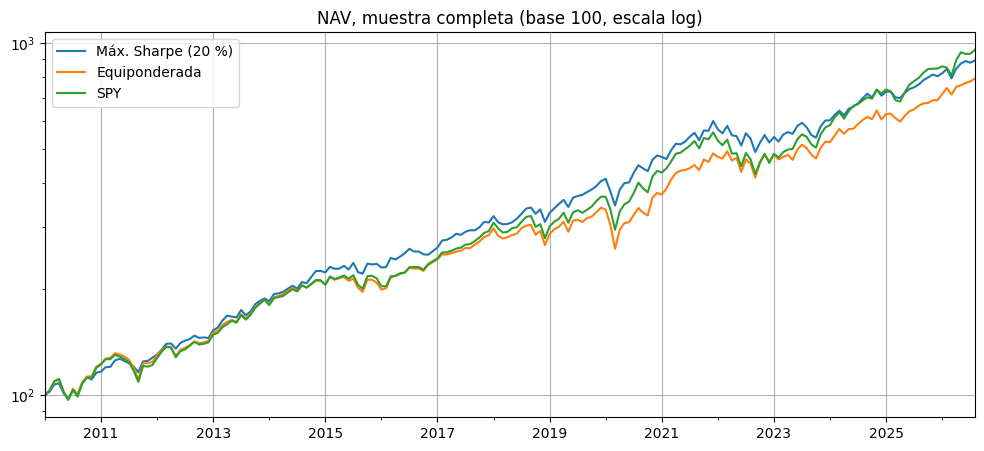

,CAGR,Annualized Volatility,Sharpe Ratio,Sortino Ratio,Maximum Drawdown,Calmar Ratio,Max Time Under Water
Máx. Sharpe (20 %),14.11%,12.01%,1.05,1.76,-18.37%,0.77,23
Equiponderada,13.30%,13.89%,0.87,1.39,-23.60%,0.56,14
SPY,14.59%,14.36%,0.93,1.51,-23.93%,0.61,23


In [19]:
def nav(returns: pd.DataFrame, weights: pd.Series) -> pd.Series:
    """NAV (base 100) de una cartera rebalanceada cada mes a pesos constantes."""
    r = returns[weights.index].dropna().dot(weights)
    start = pd.Series([100.0], index=[r.index[0] - 1])
    return pd.concat([start, 100 * (1 + r).cumprod()])


W_MS = tangency["Long-only, máx. 20 %"]

navs = pd.DataFrame({
    "Máx. Sharpe (20 %)": nav(returns, W_MS),
    "Equiponderada": nav(returns, ew_opt),
    "SPY": nav(returns, pd.Series({BENCHMARK: 1.0})),
})

COLS = ["CAGR", "Annualized Volatility", "Sharpe Ratio", "Sortino Ratio",
        "Maximum Drawdown", "Calmar Ratio", "Max Time Under Water"]
FMT = {"CAGR": "{:.2%}", "Annualized Volatility": "{:.2%}", "Sharpe Ratio": "{:.2f}",
       "Sortino Ratio": "{:.2f}", "Maximum Drawdown": "{:.2%}", "Calmar Ratio": "{:.2f}",
       "Max Time Under Water": "{:.0f}"}

full_summary = generate_risk_summary(navs, periods_per_year=12, risk_free_rate=RF_ANNUAL)
navs.set_index(navs.index.to_timestamp()).plot(logy=True, title="NAV, muestra completa (base 100, escala log)")
plt.show()
full_summary[COLS].style.format(FMT)

**Comentario:**

En la muestra completa, la cartera de máximo Sharpe (20 %) consigue el mejor riesgo ajustado: Sharpe de 1,05 frente a 0,93 de SPY y 0,87 de la equiponderada, y la menor caída máxima (−18,4 %, frente al −23,9 % de SPY). Pero **no la mayor rentabilidad**: SPY rinde más (CAGR del 14,6 % frente al 14,1 %). La optimización ha reducido el riesgo (volatilidad del 12,0 % frente al 14,4 %) más de lo que ha aumentado la rentabilidad.

Este resultado está sesgado a favor del máximo Sharpe, porque los pesos se han elegido con los mismos datos con los que se evalúa: sabiendo de antemano qué sectores iban a rendir más. Aun así, ni siquiera con esa ventaja supera a SPY en rentabilidad. La comparación honesta es la fuera de muestra (A.4).

### A.3 SML del CAPM

Para cada sector: beta contra SPY (con retornos en exceso) y rentabilidad media en exceso anualizada. Si el CAPM se cumple, los puntos están sobre la **SML teórica**: recta que pasa por el origen con pendiente igual a la prima de mercado (rentabilidad en exceso media de SPY). Se estima la recta empírica $\bar r_i = \gamma_0 + \gamma_1 \beta_i$ y se contrasta $\gamma_0 = 0$ y $\gamma_1 = $ prima de mercado.

Prima de mercado (SPY): 13.31%
γ0 = 5.23% (t = 1.42)   teoría: 0
γ1 = 6.80% (t = 1.76)   teoría: 13.31%  (t vs teoría = -1.69)
R² = 0.28


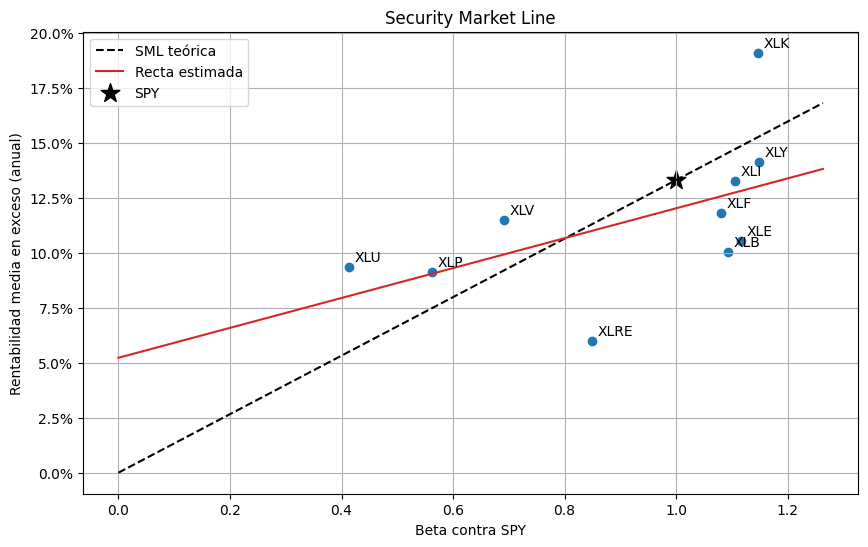

In [20]:
def capm_beta(y: pd.Series, x: pd.Series) -> float:
    data = pd.concat([y, x], axis=1).dropna()
    return sm.OLS(data.iloc[:, 0], sm.add_constant(data.iloc[:, 1])).fit().params.iloc[1]


sml = pd.DataFrame({
    "beta": {s: capm_beta(ex[s], ex[BENCHMARK]) for s in SECTORS},
    "rentabilidad exceso": ex[SECTORS].mean() * 12,
})
market_premium = ex[BENCHMARK].mean() * 12

fit = sm.OLS(sml["rentabilidad exceso"], sm.add_constant(sml["beta"])).fit()
gamma0, gamma1 = fit.params
t0, t1 = fit.tvalues
t_slope_vs_theory = (gamma1 - market_premium) / fit.bse["beta"]

print(f"Prima de mercado (SPY): {market_premium:.2%}")
print(f"γ0 = {gamma0:.2%} (t = {t0:.2f})   teoría: 0")
print(f"γ1 = {gamma1:.2%} (t = {t1:.2f})   teoría: {market_premium:.2%}  (t vs teoría = {t_slope_vs_theory:.2f})")
print(f"R² = {fit.rsquared:.2f}")

b = np.linspace(0, sml["beta"].max() * 1.1, 50)
fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(sml["beta"], sml["rentabilidad exceso"])
for s, row in sml.iterrows():
    ax.annotate(s, (row["beta"], row["rentabilidad exceso"]), xytext=(4, 4), textcoords="offset points")
ax.plot(b, market_premium * b, "k--", label="SML teórica")
ax.plot(b, gamma0 + gamma1 * b, "tab:red", label="Recta estimada")
ax.scatter(1, market_premium, marker="*", s=200, color="black", label="SPY")
ax.yaxis.set_major_formatter(PercentFormatter(1.0))
ax.set(xlabel="Beta contra SPY", ylabel="Rentabilidad media en exceso (anual)", title="Security Market Line")
ax.legend()
plt.show()

**Comentario:**

La recta estimada es **más plana que la teórica y no pasa por el origen**:

| | Estimado | Teoría CAPM | t |
|---|---|---|---|
| Intercepto γ0 | 5,23 % | 0 | 1,42 |
| Pendiente γ1 | 6,80 % | 13,31 % (prima de SPY) | 1,76 (vs 0); −1,69 (vs teoría) |
| R² | 0,28 | 1 | |

Es el patrón clásico documentado por Black, Jensen y Scholes (1972) y Frazzini y Pedersen (2014): **los sectores de beta baja rinden más de lo que predice el CAPM, y los de beta alta, menos**. Los defensivos (XLU, XLP y XLV, con betas de 0,4 a 0,7) quedan por encima de la SML teórica; los cíclicos (XLB, XLE y XLF, con betas en torno a 1,1) quedan por debajo.

Pero la evidencia es débil. Ningún coeficiente es significativo al 5 %; la pendiente solo se aleja de la teórica al 10 % (t = −1,69). Con 10 sectores y betas concentradas entre 0,4 y 1,15, el contraste tiene muy poca potencia. Además, la beta solo explica el 28 % de las diferencias de rentabilidad. Los dos casos extremos lo ilustran: **XLK** rinde muy por encima de lo que justifica su beta (19 % con beta 1,15), y **XLRE**, muy por debajo (6 % con beta 0,85). Las diferencias entre sectores vienen de algo más que la exposición al mercado, que es lo que estudia la Parte B.

### A.4 Fuera de muestra: estimar en 2010-2017, evaluar en 2019-hoy

Se estiman `mu` y `cov` solo con 2010-2017, se construyen las carteras y se mantienen esos pesos (rebalanceo mensual) desde enero de 2019. 2018 queda fuera, como pide el enunciado. Se compara lo **esperado** (lo que prometía la optimización) con lo **obtenido**.

In [21]:
ins = ex_opt.loc["2010-01":"2017-12"]
mu_in, cov_in = estimate_inputs(ins, periods_per_year=12)

oos_weights = {
    "Máx. Sharpe (long-only)": max_sharpe(mu_in, cov_in),
    "Máx. Sharpe (20 %)": max_sharpe(mu_in, cov_in, constraints=Constraints(max_weight=0.20)),
    "Mín. varianza": min_variance(cov_in),
    "Equiponderada": ew_opt,
}

oos_returns = returns.loc["2019-01":]
oos_ex = ex.loc["2019-01":]

rows = {}
for name, w in oos_weights.items():
    realized = oos_ex[OPT].dot(w)
    rows[name] = {
        "Exceso esperado": portfolio_return(w, mu_in),
        "Exceso obtenido": realized.mean() * 12,
        "Vol. esperada": portfolio_volatility(w, cov_in),
        "Vol. obtenida": realized.std() * np.sqrt(12),
        "Sharpe esperado": portfolio_return(w, mu_in) / portfolio_volatility(w, cov_in),
        "Sharpe obtenido": realized.mean() / realized.std() * np.sqrt(12),
        "N efectivo": effective_n(w),
    }
spy_oos = oos_ex[BENCHMARK]
rows["SPY"] = {"Exceso obtenido": spy_oos.mean() * 12, "Vol. obtenida": spy_oos.std() * np.sqrt(12),
               "Sharpe obtenido": spy_oos.mean() / spy_oos.std() * np.sqrt(12)}

expected_vs_realized = pd.DataFrame(rows).T
expected_vs_realized.style.format({c: "{:.1%}" for c in expected_vs_realized.columns if "Sharpe" not in c and "N " not in c} |
                                  {"Sharpe esperado": "{:.2f}", "Sharpe obtenido": "{:.2f}", "N efectivo": "{:.1f}"}, na_rep="—")

,Exceso esperado,Exceso obtenido,Vol. esperada,Vol. obtenida,Sharpe esperado,Sharpe obtenido,N efectivo
Máx. Sharpe (long-only),14.8%,11.2%,9.7%,14.5%,1.53,0.77,3.8
Máx. Sharpe (20 %),14.8%,12.1%,9.8%,14.1%,1.51,0.86,5.0
Mín. varianza,13.0%,9.8%,9.2%,12.9%,1.41,0.76,3.8
Equiponderada,13.8%,12.9%,11.6%,15.9%,1.19,0.81,9.0
SPY,—,14.9%,—,16.4%,—,0.90,—


In [22]:
pd.DataFrame(oos_weights).T.style.format("{:.1%}").set_caption("Pesos estimados con 2010-2017")

,XLK,XLF,XLE,XLV,XLI,XLY,XLP,XLU,XLB
Máx. Sharpe (long-only),12.1%,0.0%,0.0%,22.1%,0.0%,29.4%,3.3%,33.2%,0.0%
Máx. Sharpe (20 %),20.0%,0.0%,0.0%,20.0%,0.0%,20.0%,20.0%,20.0%,0.0%
Mín. varianza,7.3%,1.9%,4.7%,23.1%,0.0%,0.0%,30.7%,32.3%,0.0%
Equiponderada,11.1%,11.1%,11.1%,11.1%,11.1%,11.1%,11.1%,11.1%,11.1%


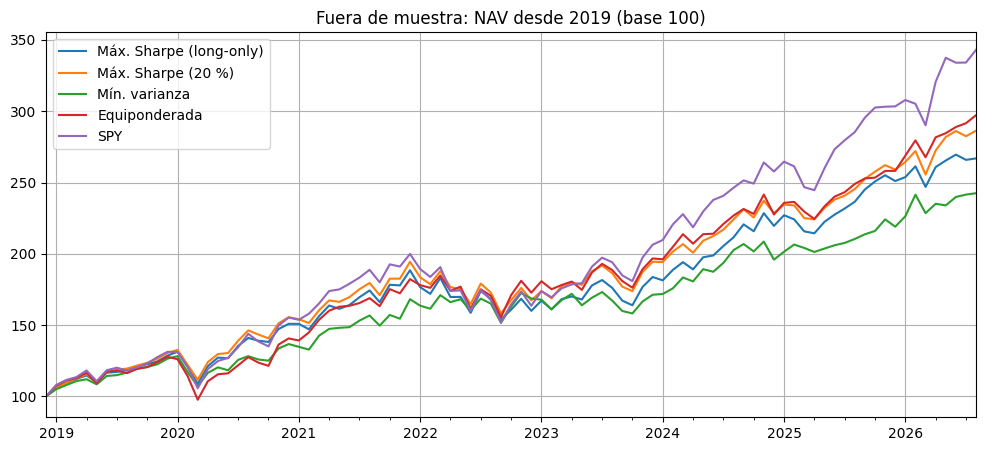

,CAGR,Annualized Volatility,Sharpe Ratio,Sortino Ratio,Maximum Drawdown,Calmar Ratio,Max Time Under Water
Máx. Sharpe (long-only),13.66%,14.48%,0.78,1.22,-18.21%,0.75,25
Máx. Sharpe (20 %),14.71%,14.05%,0.86,1.38,-18.64%,0.79,25
Mín. varianza,12.25%,12.87%,0.76,1.20,-16.43%,0.75,8
Equiponderada,15.27%,15.87%,0.81,1.28,-23.60%,0.65,14
SPY,17.45%,16.45%,0.90,1.46,-23.93%,0.73,23


In [24]:
oos_navs = pd.DataFrame({name: nav(oos_returns, w) for name, w in oos_weights.items()})
oos_navs["SPY"] = nav(oos_returns, pd.Series({BENCHMARK: 1.0}))

oos_navs.set_index(oos_navs.index.to_timestamp()).plot(title="Fuera de muestra: NAV desde 2019 (base 100)")
plt.show()

RF_OOS = rf.loc["2019-01":].mean() * 12   # tipo libre de riesgo medio del periodo evaluado
generate_risk_summary(oos_navs, periods_per_year=12, risk_free_rate=RF_OOS)[COLS].style.format(FMT)

**Comentario:**

**Lo que se esperaba frente a lo que llegó:**

| | Sharpe esperado | Sharpe obtenido | Caída | Vol. esperada | Vol. obtenida |
|---|---|---|---|---|---|
| Máx. Sharpe (long-only) | 1,53 | 0,77 | −50 % | 9,7 % | 14,5 % |
| Máx. Sharpe (20 %) | 1,51 | 0,86 | −43 % | 9,8 % | 14,1 % |
| Mín. varianza | 1,41 | 0,76 | −46 % | 9,2 % | 12,9 % |
| Equiponderada | 1,19 | 0,81 | −32 % | 11,6 % | 15,9 % |
| SPY | — | 0,90 | — | — | 16,4 % |

**1. Las carteras optimizadas prometían el doble de lo que dieron.** El Sharpe se reduce a la mitad y la volatilidad real es un 40-50 % mayor que la esperada. Parte se debe al cambio de entorno: 2010-2017 fue un mercado alcista excepcionalmente tranquilo, y 2019-2026 incluye el COVID y 2022. Por eso **incluso la equiponderada**, que no depende de ninguna estimación, cae de 1,19 a 0,81.

**2. Pero las optimizadas caen más que la equiponderada** (−43 % a −50 % frente a −32 %). Esa diferencia es el **error de estimación amplificado por el optimizador**: Markowitz trata `mu` como conocida, apuesta fuerte por los sectores que mejor lo hicieron en el pasado (XLU 33 %, XLY 29 % y XLV 22 % en la long-only) y, cuando esa historia no se repite, el error se multiplica.

**3. El límite del 20 % ayuda fuera de muestra.** La versión acotada supera a la long-only en Sharpe (0,86 frente a 0,77) y en rentabilidad (12,1 % frente a 11,2 %). Dentro de muestra, el límite costaba rentabilidad esperada (A.1); fuera de muestra la devuelve, porque obliga a no concentrarse en estimaciones poco fiables.

**4. La mínima varianza cumple lo que promete en riesgo.** Rinde menos, pero tiene la menor volatilidad (12,9 %), la menor caída máxima (−16,4 %) y la recuperación más rápida (8 meses frente a 23-25). Depende solo de la covarianza, que es mucho más estable en el tiempo que la rentabilidad esperada.

**5. SPY gana a todas.** Mayor rentabilidad en exceso (14,9 %) y mejor Sharpe (0,90). El motivo es sectorial: entre 2023 y 2026 el mercado lo han impulsado las grandes tecnológicas, y SPY tiene en torno a un 30 % en tecnología, frente al 11-20 % de las carteras construidas. Las carteras estimadas con 2010-2017 se inclinaron hacia sectores defensivos (XLU, XLP y XLV), justo lo contrario de lo que funcionó después.

**Conclusión:** la optimización media-varianza con estimaciones muestrales no ha batido ni a la equiponderada ni a SPY fuera de muestra. Lo único que ha funcionado de forma robusta es lo que no depende de `mu`: limitar la concentración y minimizar la varianza.

## Parte B — Modelos multifactoriales

`run_factor_regression` estima $r_i - r_f = \alpha + \sum_k \beta_k F_k + \varepsilon$ con errores estándar de Newey-West (robustos a heterocedasticidad y autocorrelación). Se aplica a los 10 sectores y a las carteras de la Parte A:

* **Máx. Sharpe (in-sample)**: pesos de A.2, estimados con toda la muestra. Su alfa está inflada por construcción, porque los pesos se eligieron sabiendo qué sectores iban a rendir más.
* **Máx. Sharpe (OOS)**: pesos estimados con 2010-2017 y aplicados desde 2019, sin mirar al futuro.
* **Equiponderada**.

In [12]:
portfolios_ex = pd.DataFrame({
    "Máx. Sharpe (in-sample)": ex[OPT].dot(W_MS),
    "Máx. Sharpe (OOS)": oos_ex[OPT].dot(oos_weights["Máx. Sharpe (20 %)"]),
    "Equiponderada": ex[OPT].dot(ew_opt),
})
assets_ex = ex[SECTORS].join(portfolios_ex)

table = compare_models(assets_ex, factors)

def stars(t):
    return "***" if abs(t) > 2.58 else "**" if abs(t) > 1.96 else "*" if abs(t) > 1.65 else ""

alpha_view = pd.DataFrame({
    model: [f"{a:+.2%}{stars(t)}" for a, t in zip(table[(model, "alpha (ann.)")], table[(model, "t(alpha)")])]
    for model in ["CAPM", "FF3", "Carhart", "FF5"]
}, index=table.index)
r2_view = table.xs("adj R2", axis=1, level=1)

print("Alfa anualizada (* p<0.10, ** p<0.05, *** p<0.01, Newey-West)")
alpha_view

Alfa anualizada (* p<0.10, ** p<0.05, *** p<0.01, Newey-West)


,CAPM,FF3,Carhart,FF5
XLK,+4.47%**,+3.12%*,+2.93%*,+3.66%*
XLF,-2.25%,-1.70%,-1.31%,-1.04%
XLE,-4.05%,-2.48%,-0.89%,-3.31%
XLV,+2.70%,+2.25%,+2.01%,+1.68%
XLI,-1.09%,-0.54%,-0.84%,-1.08%
XLY,-0.87%,-0.51%,-0.32%,-0.65%
XLP,+2.22%,+0.86%,+0.50%,-0.70%
XLU,+4.45%,+3.38%,+2.29%,+2.30%
XLB,-4.06%*,-3.70%*,-3.01%,-4.53%**
XLRE,-4.18%,-4.19%,-4.17%,-4.67%


In [13]:
r2_view.style.format("{:.2f}").background_gradient(axis=None, cmap="Greens").set_caption("R² ajustado")

,CAPM,FF3,Carhart,FF5
XLK,0.76,0.84,0.84,0.85
XLF,0.72,0.86,0.86,0.87
XLE,0.37,0.61,0.62,0.62
XLV,0.51,0.51,0.51,0.53
XLI,0.81,0.84,0.84,0.85
XLY,0.83,0.85,0.85,0.85
XLP,0.40,0.48,0.48,0.63
XLU,0.14,0.18,0.20,0.22
XLB,0.70,0.74,0.74,0.76
XLRE,0.53,0.53,0.52,0.56


In [14]:
ff5_full = run_factor_regression(assets_ex, factors, "FF5")
beta_cols = [c for c in ff5_full.columns if c.startswith("beta")]
ff5_full[beta_cols + ["adj R2"]].astype(float).style.format("{:.2f}").background_gradient(
    subset=beta_cols, cmap="RdBu", vmin=-1.5, vmax=1.5).set_caption("Betas FF5")

,beta Mkt-RF,beta SMB,beta HML,beta RMW,beta CMA,adj R2
XLK,1.15,-0.40,-0.21,-0.21,-0.19,0.85
XLF,1.01,-0.02,0.75,-0.08,-0.28,0.87
XLE,1.06,0.31,0.89,0.21,0.41,0.62
XLV,0.70,-0.03,-0.19,0.06,0.43,0.53
XLI,1.06,0.18,0.16,0.18,0.19,0.85
XLY,1.08,0.18,-0.18,0.18,-0.21,0.85
XLP,0.64,-0.20,-0.13,0.44,0.61,0.63
XLU,0.46,-0.19,-0.06,0.30,0.40,0.22
XLB,1.06,0.16,0.16,0.26,0.29,0.76
XLRE,0.80,0.17,-0.12,0.33,0.24,0.56


### Betas rolling (36 meses)

XLK (tecnología) y XLE (energía) tienen exposiciones opuestas al factor valor: la tecnología es el ejemplo clásico de *growth* (HML negativo) y la energía de *value* (HML positivo).

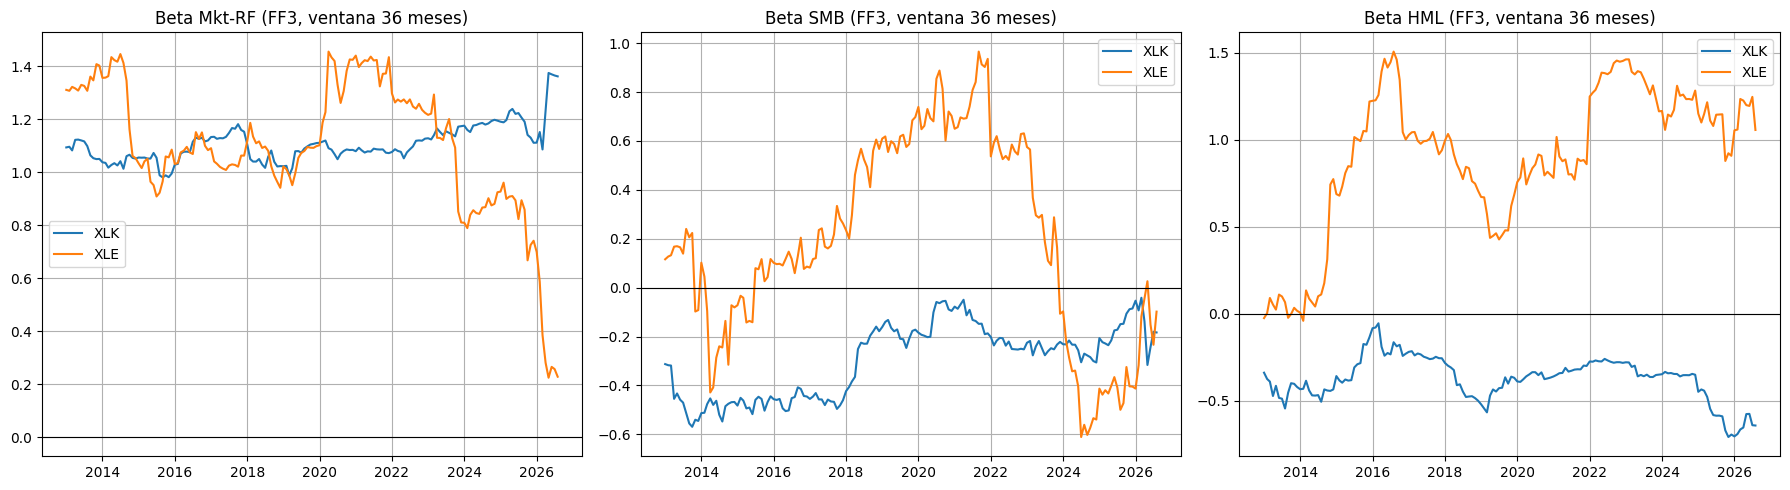

In [15]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharex=True)
for sector, color in [("XLK", "tab:blue"), ("XLE", "tab:orange")]:
    rb = rolling_betas(ex[sector], factors, "FF3", window=36)
    rb.index = rb.index.to_timestamp()
    for ax, factor in zip(axes, ["Mkt-RF", "SMB", "HML"]):
        ax.plot(rb.index, rb[factor], color=color, label=sector)
for ax, factor in zip(axes, ["Mkt-RF", "SMB", "HML"]):
    ax.axhline(0, color="black", lw=0.8)
    ax.set_title(f"Beta {factor} (FF3, ventana 36 meses)")
    ax.legend()
plt.tight_layout()
plt.show()

## Discusión (máx. 500 palabras)

**¿Sobrevive alguna alfa al pasar de CAPM a FF5?**

_(Completar.)_

**¿Qué gana el modelo de cinco factores sobre el de tres en este universo?**

_(Completar.)_

**¿Cuánto del resultado de la cartera óptima es exposición factorial disfrazada de habilidad?**

_(Completar.)_

## Conclusiones

_(Completar.)_